<a href="https://colab.research.google.com/github/nasif-raihan/GSU/blob/main/CSCI_7090_Module10_Lab2_SSDInference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 10 — SSD Inference on an Image (Lab)
**Computer Vision · Object Detection**

Run a **pretrained SSD** on a real image and draw the detected boxes. Uses torchvision's built-in `ssd300_vgg16` (clean, current API) instead of downloading a model archive by hand. Best run in Colab.

## 1. Load a pretrained SSD
`weights=DEFAULT` downloads the COCO-trained SSD and its matching preprocessing + class names.

In [1]:
import torch
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights

weights = SSD300_VGG16_Weights.DEFAULT
model = ssd300_vgg16(weights=weights).eval()
preprocess = weights.transforms()
categories = weights.meta["categories"]
print("classes the model knows:", len(categories))

classes the model knows: 91


## 2. Load an image
In Colab, upload one with `files.upload()`, or point `read_image` at any local path.

In [5]:
from torchvision.io import read_image
# from google.colab import files; up = files.upload(); path = list(up.keys())[0]
path = "/content/eagle.jpg"          # <- set to your image
img = read_image(path)           # uint8 tensor, shape (3, H, W)
print("image shape:", tuple(img.shape))

image shape: (3, 554, 554)


## 3. Detect

In [6]:
with torch.no_grad():
    pred = model([preprocess(img)])[0]

score_thresh = 0.5
keep = pred["scores"] > score_thresh
boxes  = pred["boxes"][keep]
labels = [categories[i] for i in pred["labels"][keep]]
scores = pred["scores"][keep]
print(f"{keep.sum().item()} detections above {score_thresh}")

1 detections above 0.5


## 4. Draw the results
We draw with Matplotlib so the cell is easy to read; each box shows its label and confidence.

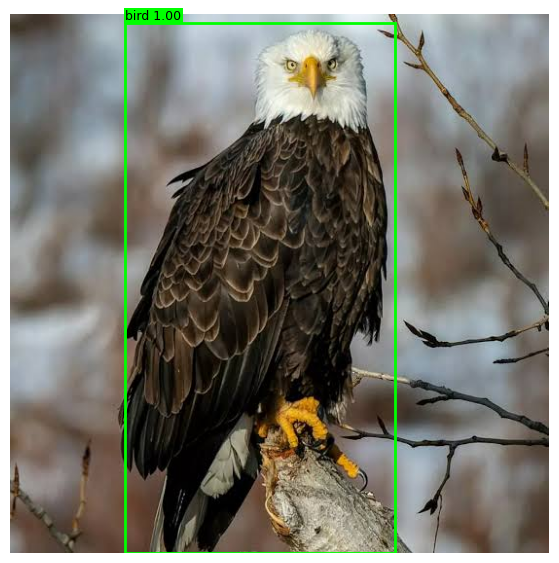

In [7]:
import matplotlib.pyplot as plt, matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(img.permute(1, 2, 0))          # CHW -> HWC for display
for (x1, y1, x2, y2), lab, sc in zip(boxes.tolist(), labels, scores.tolist()):
    ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="lime", lw=2))
    ax.text(x1, y1-4, f"{lab} {sc:.2f}", color="black",
            bbox=dict(facecolor="lime", edgecolor="none", pad=1), fontsize=9)
ax.axis("off"); plt.show()

**Pipeline recap (from the doc):** preprocess → forward pass through base + extra layers → per-scale predictions → confidence threshold → (NMS, applied internally by torchvision) → final boxes drawn.